# 05 — Autograd

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–04, especially 03 (derivatives, Jacobians, vector–Jacobian products, finite differences) |
| **You will learn** | How PyTorch records a computational graph and runs it backwards; why backward is a chain of vector–Jacobian products; leaf tensors and `.grad`; gradient accumulation; `detach`, `no_grad`, and `inference_mode`; in-place traps; writing a custom `torch.autograd.Function` and verifying it with `gradcheck`; second derivatives |
| **Estimated time** | 3 hours |
| **Compute** | CPU. One optional GPU cell. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math
import time
import warnings

from dlcourse.plotting import COLORS

## Motivating problem

In notebook 03 you differentiated functions by hand and checked the results with finite differences. That works for a function of two or three variables. A neural network's loss is a function of millions of parameters:

- Deriving its gradient by hand is impractical, and every change to the model would mean deriving it again.
- A central finite difference needs **two** evaluations of the loss **per parameter**: for a million parameters, two million forward passes for a single gradient — and the result is only approximate.

Yet PyTorch returns the exact gradient (up to floating-point rounding) of almost any expression you write, at a cost of roughly one extra forward pass. **How?** This notebook opens the box: PyTorch records every operation as you compute, then runs the chain rule backwards through that record, one vector–Jacobian product at a time.

## 1. `requires_grad` and a first `backward()`

A tensor created with `requires_grad=True` tells PyTorch: *"I will want derivatives with respect to this tensor."* From then on, every operation that uses it is recorded. Calling `.backward()` on a **scalar** result computes the derivative of that scalar with respect to every such tensor and stores it in the tensor's `.grad` attribute.

Take $f(x) = x^3 - 2x$. By hand, $f'(x) = 3x^2 - 2$, so $f'(1.5) = 3 \cdot 2.25 - 2 = 4.75$.

In [3]:
x = torch.tensor(1.5, requires_grad=True)  # shape (): a scalar we will differentiate with respect to
f = x**3 - 2 * x                           # PyTorch records the operations as it computes f
print("f(1.5)   =", f.item())
print("x.grad before backward:", x.grad)

f.backward()                               # compute df/dx and store it in x.grad
print("x.grad after backward: ", x.grad.item())
print("hand derivative 3x²-2: ", 3 * 1.5**2 - 2)

f(1.5)   = 0.375
x.grad before backward: None
x.grad after backward:  4.75
hand derivative 3x²-2:  4.75


Before `backward()`, `x.grad` is `None`: no gradient has been computed yet. After it, `x.grad` holds $f'(1.5)$.

Compare with a central finite difference from notebook 03, $f'(x) \approx \dfrac{f(x+h) - f(x-h)}{2h}$. We use `float64` and $h = 10^{-5}$; the approximation error is of order $h^2$ plus rounding.

In [4]:
def f_scalar(t):
    return t**3 - 2 * t

h = 1e-5
x64 = torch.tensor(1.5, dtype=torch.float64)
central = (f_scalar(x64 + h) - f_scalar(x64 - h)) / (2 * h)
print(f"central difference: {central.item():.12f}")
print(f"autograd:           {x.grad.item():.12f}")

central difference: 4.750000000131
autograd:           4.750000000000


They agree to about 10 digits (autograd ran in `float32`, so its value is exact only to about 7 digits; it prints as 4.75 because 4.75 is exactly representable). The finite difference needed two function evaluations for one derivative; autograd needed one forward computation and one backward pass.

The derivative is the slope of the tangent line. The plot draws $f$ and the line through $(1.5, f(1.5))$ with the slope autograd returned.

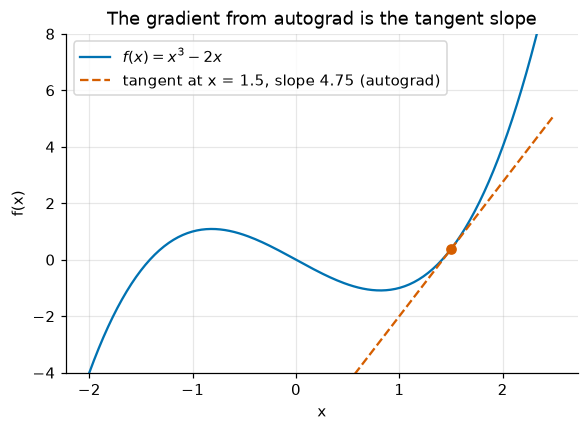

In [5]:
xs = torch.linspace(-2, 2.5, 200)
slope = x.grad.item()
x0, f0 = 1.5, f_scalar(torch.tensor(1.5)).item()
plt.plot(xs, f_scalar(xs), label="$f(x) = x^3 - 2x$")
plt.plot(xs, f0 + slope * (xs - x0), "--", label=f"tangent at x = 1.5, slope {slope:.2f} (autograd)")
plt.plot([x0], [f0], "o", color=COLORS[1])
plt.ylim(-4, 8)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("The gradient from autograd is the tangent slope")
plt.legend()
plt.show()

The dashed line touches the curve at $x = 1.5$ and has the same slope there, which is what a derivative means.

With several inputs, `backward()` fills `.grad` of each one with the corresponding partial derivative. For $g(a, b) = a b + b^2$: $\partial g/\partial a = b$ and $\partial g/\partial b = a + 2b$.

In [6]:
a = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(-1.0, requires_grad=True)
g = a * b + b**2
g.backward()
print("dg/da =", a.grad.item(), " (hand: b =", b.item(), ")")
print("dg/db =", b.grad.item(), " (hand: a + 2b =", (a + 2 * b).item(), ")")

dg/da = -1.0  (hand: b = -1.0 )
dg/db = 0.0  (hand: a + 2b = 0.0 )


For a vector input, `.grad` has the same shape as the input. For $s(\mathbf{x}) = \sum_i x_i^2$, the gradient is $\nabla s = 2\mathbf{x}$:

In [7]:
xv = torch.tensor([1.0, -2.0, 3.0], requires_grad=True)  # (3,)
s = (xv**2).sum()                                         # scalar
s.backward()
print("xv.grad =", xv.grad, " shape", tuple(xv.grad.shape))
print("2 * xv  =", 2 * xv.detach())

xv.grad = tensor([ 2., -4.,  6.])  shape (3,)
2 * xv  = tensor([ 2., -4.,  6.])


(`.detach()` here just gives a copy of the values without gradient tracking, for printing; section 6 explains it.)

Where a function has no derivative, autograd still has to return a number. Notebook 03 noted that ReLU has a kink at 0 and that PyTorch uses the slope from the left, 0. Autograd confirms it:

In [8]:
xr = torch.tensor([-1.0, 0.0, 1.0], requires_grad=True)
torch.relu(xr).sum().backward()
print("d relu / dx at -1, 0, 1:", xr.grad)

d relu / dx at -1, 0, 1: tensor([0., 0., 1.])


### Checkpoint 1.1

Let $p(x) = 4x^3 - x^2 + 7$. Use autograd to compute $p'(2)$ and store it as a Python float in `p_prime`. Then work out $p'(2)$ by hand and compare.

<details>
<summary><b>💡 Hint</b></summary>

Create `xp = torch.tensor(2.0, requires_grad=True)`, compute `p` from it, call `p.backward()`, and read `xp.grad.item()`. By hand, $p'(x) = 12x^2 - 2x$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check(isinstance(p_prime, float), f"p_prime should be a Python float (use .item()), got {type(p_prime).__name__}")
check_close(p_prime, 12 * 2.0**2 - 2 * 2.0, "p_prime")
passed("Checkpoint 1.1")

## 2. The computational graph

While you compute, PyTorch builds a **computational graph**: a record of which operations produced which tensors. Every tensor produced by a recorded operation carries a `grad_fn` attribute — the node that knows how to send gradients back through that operation. Each node lists its inputs' nodes in `next_functions`.

Consider a one-parameter-pair prediction and its squared error:

$$L = (w x + b - 5)^2, \qquad w = 3,\; b = 1,\; x = 2.$$

We want derivatives with respect to $w$ and $b$, but not $x$ (think of $x$ as data).

In [11]:
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
x = torch.tensor(2.0)                    # data: requires_grad defaults to False

prod = w * x                             # 6
pred = prod + b                          # 7
err = pred - 5                           # 2
L = err**2                               # 4
for name, t in [("w", w), ("x", x), ("prod", prod), ("pred", pred), ("err", err), ("L", L)]:
    print(f"{name:>5}: value {t.item():>4}, grad_fn = {t.grad_fn}")

    w: value  3.0, grad_fn = None
    x: value  2.0, grad_fn = None
 prod: value  6.0, grad_fn = <MulBackward0 object at 0x11ea57880>
 pred: value  7.0, grad_fn = <AddBackward0 object at 0x11e7d6050>
  err: value  2.0, grad_fn = <SubBackward0 object at 0x11eb0b280>
    L: value  4.0, grad_fn = <PowBackward0 object at 0x11eb0b2b0>


`w`, `b` and `x` were created directly, so they have no `grad_fn`. Each intermediate tensor names the operation that made it: `MulBackward0`, `AddBackward0`, `SubBackward0`, `PowBackward0`. Starting from `L.grad_fn` and following `next_functions` walks the whole graph backwards:

In [12]:
print(L.grad_fn.next_functions)
print(err.grad_fn.next_functions)

((<SubBackward0 object at 0x11eb0b280>, 0),)
((<AddBackward0 object at 0x11e7d6050>, 0), (None, 0))


Each entry is a pair `(node, index)`. `(None, 0)` marks an input that needs no gradient — here the constant `5`. A short recursive helper prints the full graph. `AccumulateGrad` is the special node that deposits a gradient into a leaf's `.grad`; its `.variable` attribute is that leaf tensor.

In [13]:
def print_graph(fn, names=None, indent=0):
    """Print the backward graph that starts at grad_fn `fn`, one node per line.

    `names` optionally maps a display name to a leaf tensor, so leaves are labelled.
    """
    if fn is None:
        return
    label = type(fn).__name__
    if hasattr(fn, "variable"):  # an AccumulateGrad node: writes into a leaf's .grad
        leaf_name = next((n for n, t in (names or {}).items() if t is fn.variable), "?")
        label += f"  → .grad of leaf '{leaf_name}'"
    print("    " * indent + label)
    for child, _ in fn.next_functions:
        print_graph(child, names, indent + 1)


print_graph(L.grad_fn, names={"w": w, "b": b})

PowBackward0
    SubBackward0
        AddBackward0
            MulBackward0
                AccumulateGrad  → .grad of leaf 'w'
            AccumulateGrad  → .grad of leaf 'b'


Read it from the top: $L$ came from a power, whose input came from a subtraction, whose input came from an addition of (a multiplication involving $w$) and $b$. The data tensor $x$ does not appear: nothing needs a gradient through it, so autograd does not record a path to it.

**Leaves.** A tensor is a **leaf** if it was not produced by a recorded operation — you created it directly. `w`, `b` and `x` are leaves; `prod`, `pred`, `err` and `L` are not. By default, `backward()` stores gradients only in leaves that have `requires_grad=True`. Those are normally a model's parameters, which are exactly what we need gradients for.

In [14]:
L.backward()
for name, t in [("w", w), ("b", b), ("x", x), ("pred", pred)]:
    print(f"{name:>4}: is_leaf={t.is_leaf!s:5}  requires_grad={t.requires_grad!s:5}")
print("w.grad =", w.grad.item(), "  hand: 2(wx+b-5)·x =", 2 * 2 * 2.0)
print("b.grad =", b.grad.item(), "  hand: 2(wx+b-5)   =", 2 * 2.0)
print("x.grad =", x.grad)

   w: is_leaf=True   requires_grad=True 
   b: is_leaf=True   requires_grad=True 
   x: is_leaf=True   requires_grad=False
pred: is_leaf=False  requires_grad=True 
w.grad = 8.0   hand: 2(wx+b-5)·x = 8.0
b.grad = 4.0   hand: 2(wx+b-5)   = 4.0
x.grad = None


`x.grad` is `None` because `x` does not require a gradient. Reading `.grad` of an intermediate tensor also gives `None`, and PyTorch warns you, because it is almost always a mistake:

In [15]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    print("pred.grad =", pred.grad)
print("UserWarning:", str(caught[0].message)[:105], "...")

pred.grad = None


Intermediate gradients are computed during the backward pass — they must be, to reach the leaves — but they are discarded to save memory. If you want to inspect one, call `.retain_grad()` on it **before** `backward()`:

In [16]:
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)
pred = w * x + b
pred.retain_grad()                 # keep dL/dpred after backward
L = (pred - 5) ** 2
L.backward()
print("dL/dpred =", pred.grad.item(), "  hand: 2(pred - 5) =", 2 * (7 - 5))

dL/dpred = 4.0   hand: 2(pred - 5) = 4


### Checkpoint 2.1

Without running anything new, look at the cell below and decide which tensors are leaves, and which will have a non-`None` `.grad` after `t.backward()`. Store the names as sets of strings in `leaves` and `has_grad`, e.g. `{"u", "s"}`.

In [17]:
u = torch.tensor(1.5, requires_grad=True)
v = torch.tensor(-0.5)
s = u * v
t = s.tanh() + u
t.backward()

<details>
<summary><b>💡 Hint</b></summary>

Leaves are the tensors you created with `torch.tensor(...)`, whether or not they require gradients. Only leaves with `requires_grad=True` receive `.grad`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check(isinstance(leaves, set) and isinstance(has_grad, set), "leaves and has_grad should both be Python sets of names")
_tensors = {"u": u, "v": v, "s": s, "t": t}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # reading .grad of non-leaves warns
    check(leaves == {n for n, z in _tensors.items() if z.is_leaf}, "leaves: which tensors were created directly rather than by an operation?")
    check(has_grad == {n for n, z in _tensors.items() if z.grad is not None}, "has_grad: by default only leaves that require grad get .grad")
passed("Checkpoint 2.1")

## 3. How `backward()` works: a chain of vector–Jacobian products

Notebook 03 showed that for a composition $\mathbf{x} \to \mathbf{u} \to \mathbf{v} \to L$ with scalar $L$, the chain rule multiplies Jacobians:

$$\frac{\partial L}{\partial \mathbf{x}} = \frac{\partial L}{\partial \mathbf{v}}\, J_{\mathbf{v}}(\mathbf{u})\, J_{\mathbf{u}}(\mathbf{x}),$$

where $J_{\mathbf{v}}(\mathbf{u})$ is the Jacobian of $\mathbf{v}$ with respect to $\mathbf{u}$, and $\partial L / \partial \mathbf{v}$ is a row vector. Matrix multiplication is associative, so we may evaluate this product in any order. **Reverse mode** evaluates it from the left: start with the row vector $\partial L/\partial \mathbf{v}$ and multiply by one Jacobian at a time. Every step is a **vector–Jacobian product** (VJP): a row vector times a matrix gives a row vector. The full Jacobians are never formed.

That is all `backward()` does. Each `grad_fn` node implements one VJP: given the gradient of $L$ with respect to its output (called the **upstream gradient**), it returns the gradient with respect to its inputs. The forward pass saves whatever values these VJPs will need.

### A 3-step chain by hand

Let $x = 0.5$ and

$$u = x^2, \qquad v = \sin u, \qquad L = e^{v}.$$

**Forward pass:** compute and store $u$, $v$, $L$.

**Local derivatives:** $\dfrac{du}{dx} = 2x$, $\dfrac{dv}{du} = \cos u$, $\dfrac{dL}{dv} = e^{v}$.

**Backward pass:** write $\bar{z}$ for $\partial L / \partial z$, the gradient of $L$ with respect to $z$. Start from $\bar{L} = 1$ and multiply by one local derivative per step:

$$\bar{v} = \bar{L}\, e^{v}, \qquad \bar{u} = \bar{v} \cos u, \qquad \bar{x} = \bar{u} \cdot 2x.$$

In [20]:
x_val = 0.5
# Forward pass: compute and remember intermediate values
u_val = x_val**2
v_val = math.sin(u_val)
L_val = math.exp(v_val)
print(f"forward:   u = {u_val:.6f}   v = {v_val:.6f}   L = {L_val:.6f}")

# Backward pass: start with dL/dL = 1, multiply by one local derivative per step
L_bar = 1.0
v_bar = L_bar * math.exp(v_val)   # dL/dv = e^v   (uses the saved v, or equivalently L)
u_bar = v_bar * math.cos(u_val)   # dv/du = cos u (uses the saved u)
x_bar = u_bar * 2 * x_val         # du/dx = 2x    (uses the saved x)
print(f"backward:  v̄ = {v_bar:.6f}   ū = {u_bar:.6f}   x̄ = {x_bar:.6f}")

forward:   u = 0.250000   v = 0.247404   L = 1.280696
backward:  v̄ = 1.280696   ū = 1.240883   x̄ = 1.240883


Now let autograd do the same, keeping the intermediate gradients with `retain_grad()` so we can compare every number:

In [21]:
xt = torch.tensor(0.5, dtype=torch.float64, requires_grad=True)
ut = xt**2
vt = torch.sin(ut)
Lt = torch.exp(vt)
for z in (ut, vt, Lt):
    z.retain_grad()
Lt.backward()
print(f"autograd:  v̄ = {vt.grad.item():.6f}   ū = {ut.grad.item():.6f}   x̄ = {xt.grad.item():.6f}")
print("L̄ =", Lt.grad.item(), "(backward() starts from dL/dL = 1)")

autograd:  v̄ = 1.280696   ū = 1.240883   x̄ = 1.240883
L̄ = 1.0 (backward() starts from dL/dL = 1)


Every number matches. Note what the backward pass needed: the **saved forward values** $x$, $u$, $v$. That is why autograd keeps intermediate tensors alive until `backward()` runs, and why training uses much more memory than evaluation.

### The same idea with vectors

Now let $\mathbf{x}$ have $D = 4$ entries, $W$ be a $(3, 4)$ matrix, and

$$\mathbf{u} = W\mathbf{x}, \qquad \mathbf{v} = \tanh(\mathbf{u}), \qquad L = \sum_i v_i^2.$$

The VJPs, each derived from the Jacobian in notebook 03's style:

- $L = \sum_i v_i^2$: $\bar{\mathbf{v}} = 2\mathbf{v}$, shape $(3,)$.
- $\mathbf{v} = \tanh(\mathbf{u})$ elementwise: the Jacobian is diagonal with entries $1 - v_i^2$, so the VJP is an elementwise product, $\bar{\mathbf{u}} = \bar{\mathbf{v}} \odot (1 - \mathbf{v}^2)$, shape $(3,)$.
- $\mathbf{u} = W\mathbf{x}$: the Jacobian is $W$, so $\bar{\mathbf{x}} = \bar{\mathbf{u}}^\top W$, shape $(4,)$. In code, `u_bar @ W`.

In [22]:
set_seed(0)
W = torch.randn(3, 4, dtype=torch.float64)                       # (3, 4)
xvec = torch.randn(4, dtype=torch.float64, requires_grad=True)  # (4,)

uvec = W @ xvec                  # (3,)
vvec = torch.tanh(uvec)          # (3,)
Lvec = (vvec**2).sum()           # scalar
Lvec.backward()

# Manual reverse pass with the saved forward values
with torch.no_grad():            # plain arithmetic, not recorded (section 6)
    v_bar = 2 * vvec             # (3,)
    u_bar = v_bar * (1 - vvec**2)  # (3,)  diagonal Jacobian → elementwise product
    x_bar = u_bar @ W            # (4,)  row vector times Jacobian W
print("manual VJP chain:", x_bar)
print("autograd:        ", xvec.grad)
print("max difference:  ", (x_bar - xvec.grad).abs().max().item())

manual VJP chain: tensor([ 1.3721,  0.4296, -2.3528, -0.0045], dtype=torch.float64)
autograd:         tensor([ 1.3721,  0.4296, -2.3528, -0.0045], dtype=torch.float64)
max difference:   2.220446049250313e-16


Identical up to rounding. Notice the tanh step: its Jacobian is a $3 \times 3$ diagonal matrix, but the VJP never builds it — it is an elementwise product. For a layer with a million units, the Jacobian would have $10^{12}$ entries, while the VJP touches only $10^6$ numbers. Exploiting this structure is what makes backward cheap.

### How expensive is backward?

Each VJP costs about the same as the forward operation it reverses (for elementwise operations, a couple of multiplications per entry; for $W\mathbf{x}$, one matrix–vector product). A standard result of automatic differentiation, which we **state without proof**, is that the gradient of a scalar function costs a **small constant multiple** of one function evaluation — a bound of about 4–5 forward costs is often quoted — **no matter how many inputs there are**. Finite differences, by contrast, cost $2n$ evaluations for $n$ inputs.

A rough timing on $f(\mathbf{x}) = \sum_i \sin(x_i)\, x_i^2$ with two million inputs (timings depend on your machine; only the ratio matters):

In [23]:
def f_sum(x):
    return (torch.sin(x) * x**2).sum()

n_big = 2_000_000
x_big = torch.randn(n_big, generator=torch.Generator().manual_seed(1), requires_grad=True)

forward_times, total_times = [], []
for _ in range(7):
    start = time.perf_counter()
    with torch.no_grad():
        f_sum(x_big)                 # forward only
    forward_times.append(time.perf_counter() - start)

    start = time.perf_counter()
    f_sum(x_big).backward()          # forward (recorded) + backward
    total_times.append(time.perf_counter() - start)
    x_big.grad = None

t_fwd = sorted(forward_times)[3]  # median of 7
t_tot = sorted(total_times)[3]
print(f"forward only:          {1e3 * t_fwd:7.1f} ms")
print(f"forward + backward:    {1e3 * t_tot:7.1f} ms   ({t_tot / t_fwd:.1f}× the forward cost)")
print(f"central differences would need {2 * n_big:,} evaluations ≈ {2 * n_big * t_fwd / 60:,.0f} minutes at this speed")

forward only:              1.0 ms
forward + backward:        2.9 ms   (2.7× the forward cost)
central differences would need 4,000,000 evaluations ≈ 70 minutes at this speed


Forward plus backward costs a few forward passes; finite differences would take on the order of an hour (on a typical laptop) for this one gradient. This gap — a constant factor versus a factor of $2n$ — is the answer to the motivating question.

### Checkpoint 3.1

For $x = 2$, $u = 3x$, $v = u^2$, $L = \ln v$, carry out the backward pass by hand in Python (plain floats, no autograd): compute `g_v` $= \bar{v}$, `g_u` $= \bar{u}$, `g_x` $= \bar{x}$ in that order, each from the previous one. Use $\dfrac{d}{dv}\ln v = 1/v$.

<details>
<summary><b>💡 Hint</b></summary>

$\bar{v} = 1/v$; then $\bar{u} = \bar{v} \cdot 2u$; then $\bar{x} = \bar{u} \cdot 3$. As a sanity check, $L = \ln(9x^2) = \ln 9 + 2\ln x$, so $\bar{x}$ should be $2/x$.

</details>

In [ ]:
x_c = 2.0
u_c = 3 * x_c
v_c = u_c**2
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
_x = torch.tensor(2.0, dtype=torch.float64, requires_grad=True)
_u = 3 * _x
_v = _u**2
_u.retain_grad()
_v.retain_grad()
torch.log(_v).backward()
check_close(g_v, _v.grad.item(), "g_v")
check_close(g_u, _u.grad.item(), "g_u")
check_close(g_x, _x.grad.item(), "g_x")
passed("Checkpoint 3.1")

## 4. Non-scalar outputs and the functional interface

What if the output is a vector? Take $\mathbf{y} = W\mathbf{x}$ with $W$ of shape $(3, 4)$. There is no single "gradient" of a vector; there is a $3 \times 4$ Jacobian. `backward()` refuses to guess:

In [26]:
set_seed(1)
W = torch.randn(3, 4)                       # (3, 4)
x = torch.randn(4, requires_grad=True)      # (4,)
y = W @ x                                   # (3,)
try:
    y.backward()
except RuntimeError as error:
    print("RuntimeError:", str(error).splitlines()[0])

RuntimeError: grad can be implicitly created only for scalar outputs


Because backward computes VJPs, it needs the vector $\mathbf{v}$ to start from: pass it as the `gradient` argument (shape of $\mathbf{y}$). The result in `x.grad` is $\mathbf{v}^\top J = \mathbf{v}^\top W$. Equivalently, it is the ordinary gradient of the scalar $s = \mathbf{v} \cdot \mathbf{y}$, because $\partial s/\partial \mathbf{x} = \mathbf{v}^\top \partial\mathbf{y}/\partial\mathbf{x}$. When $\mathbf{y}$ is a scalar, PyTorch silently uses $v = 1$, which is the $\bar{L} = 1$ we started from in section 3.

In [27]:
v = torch.tensor([1.0, -2.0, 0.5])          # (3,): one weight per output
y.backward(gradient=v)
print("x.grad =", x.grad)
print("v @ W  =", v @ W)

x.grad = tensor([ 1.0514,  0.3177,  2.6611, -0.1712])
v @ W  = tensor([ 1.0514,  0.3177,  2.6611, -0.1712])


**`torch.autograd.grad`** is the functional form. It takes outputs, inputs and `grad_outputs` (the same $\mathbf{v}$), and **returns** the gradients as a tuple instead of writing into `.grad`. This is handy when you want a gradient as a value — and it leaves `.grad` untouched.

In [28]:
x.grad = None
y = W @ x
(vjp,) = torch.autograd.grad(y, x, grad_outputs=v)
print("autograd.grad:", vjp)
print("x.grad still: ", x.grad)

autograd.grad: tensor([ 1.0514,  0.3177,  2.6611, -0.1712])
x.grad still:  None


To see the whole Jacobian, `torch.autograd.functional.jacobian` builds it, one VJP per output row. For a nonlinear function, $\mathbf{y} = \tanh(W\mathbf{x})$, the Jacobian is $\operatorname{diag}(1 - \mathbf{y}^2)\, W$ (chain rule), and the VJP from autograd must equal $\mathbf{v}^\top J$:

In [29]:
def layer(x):
    return torch.tanh(W @ x)                 # (4,) -> (3,)

J = torch.autograd.functional.jacobian(layer, x.detach())   # (3, 4)
y_val = layer(x.detach())
J_hand = torch.diag(1 - y_val**2) @ W
print("Jacobian shape:", tuple(J.shape))
print("max |J - diag(1-y²) W| =", (J - J_hand).abs().max().item())

(vjp,) = torch.autograd.grad(layer(x), x, grad_outputs=v)
print("VJP from autograd:", vjp)
print("v @ J:            ", v @ J)

Jacobian shape: (3, 4)
max |J - diag(1-y²) W| = 0.0
VJP from autograd: tensor([ 1.0126,  0.3131,  2.4635, -0.1291])
v @ J:             tensor([ 1.0126,  0.3131,  2.4635, -0.1291])


Building the full Jacobian took 3 backward passes here (one per output). For a scalar loss there is only one output, so one backward pass gives the whole gradient. That is why training always reduces to a **scalar** loss — reverse mode is cheap exactly in that case.

### Checkpoint 4.1

For $g(\mathbf{x}) = \sin(\mathbf{x}) \cdot \sum_j x_j$ (a vector of shape $(3,)$), compute the VJP $\mathbf{v}^\top J_g(\mathbf{x}_0)$ with `torch.autograd.grad` and store it in `vjp_g`. Use the given `x0` and `v_g`.

<details>
<summary><b>💡 Hint</b></summary>

`torch.autograd.grad(outputs, inputs, grad_outputs=...)` returns a tuple with one entry per input. Unpack it with `(vjp_g,) = ...`.

</details>

In [ ]:
x0 = torch.tensor([0.3, -1.2, 2.0], requires_grad=True)   # (3,)
v_g = torch.tensor([1.0, 0.5, -1.0])                       # (3,)

def g_fn(x):
    return torch.sin(x) * x.sum()                          # (3,) -> (3,)

# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_shape(vjp_g, (3,), "vjp_g")
_J = torch.autograd.functional.jacobian(g_fn, x0.detach())
check_close(vjp_g, v_g @ _J, "vjp_g")
passed("Checkpoint 4.1")

## 5. Gradient accumulation

`backward()` does not overwrite `.grad`; it **adds** to it. Run backward twice on freshly built graphs of $f(x) = x^2$ at $x = 3$ (where $f'(3) = 6$):

In [32]:
x = torch.tensor(3.0, requires_grad=True)
(x**2).backward()
print("after first backward: ", x.grad.item())
(x**2).backward()
print("after second backward:", x.grad.item(), "← 6 + 6, not 6")

after first backward:  6.0
after second backward: 12.0 ← 6 + 6, not 6


To start fresh, reset the gradient. Either set it to `None` (frees the memory; the next backward allocates a new tensor) or zero it in place with `.zero_()`:

In [33]:
x.grad = None
(x**2).backward()
print("after x.grad = None:  ", x.grad.item())
x.grad.zero_()
(x**2).backward()
print("after x.grad.zero_(): ", x.grad.item())

after x.grad = None:   6.0
after x.grad.zero_():  6.0


**Why accumulate?** Because the derivative of a sum is the sum of the derivatives. If a loss is a sum of pieces, $L = L_1 + L_2$, then backward on each piece separately adds up to exactly the gradient of $L$. Here the loss is the sum of squared errors of a constant prediction $w$ against six data points, $L(w) = \sum_i (w - d_i)^2$:

In [34]:
data = torch.tensor([1.0, 2.0, 4.0, 3.0, 0.0, 2.0])       # (6,)

w = torch.tensor(0.5, requires_grad=True)
((w - data) ** 2).sum().backward()                     # whole loss at once
grad_whole = w.grad.clone()

w.grad = None
for chunk in data.split(3):                            # two chunks of 3 points
    ((w - chunk) ** 2).sum().backward()                # gradients add up in w.grad
print("gradient of the whole loss: ", grad_whole.item())
print("sum over two chunks:        ", w.grad.item())
print("hand: Σ 2(w - d_i) =        ", (2 * (0.5 - data)).sum().item())

gradient of the whole loss:  -18.0
sum over two chunks:         -18.0
hand: Σ 2(w - d_i) =         -18.0


Later in the course this lets us process a batch too large for memory in pieces and still get the full-batch gradient ("gradient accumulation"). The price is that **you** must reset gradients before each new gradient computation. Forgetting to is one of the most common training bugs; the debug exercise shows its effect.

### Backward twice through the same graph

The example above rebuilt the graph each time. Calling `backward()` twice on **the same** graph fails: to save memory, backward frees the saved tensors as soon as it has used them.

In [35]:
x = torch.tensor(3.0, requires_grad=True)
y = torch.exp(x) * x          # exp and mul both save tensors for backward
y.backward()
try:
    y.backward()
except RuntimeError as error:
    print("RuntimeError:", str(error).splitlines()[0][:100] + " ...")

RuntimeError: Trying to backward through the graph a second time (or directly access saved tensors after they have ...


Pass `retain_graph=True` to keep the saved tensors for another pass. The second pass then accumulates as usual: $\frac{d}{dx}(x e^x) = (x + 1)e^x$, so we expect $4e^3 \approx 80.34$, then twice that.

In [36]:
x = torch.tensor(3.0, requires_grad=True)
y = torch.exp(x) * x
y.backward(retain_graph=True)
print("first:  ", x.grad.item(), "  hand (x+1)e^x =", 4 * math.exp(3))
y.backward()
print("second: ", x.grad.item(), "  (accumulated)")

first:   80.34214782714844   hand (x+1)e^x = 80.34214769275067
second:  160.68429565429688   (accumulated)


You will rarely need `retain_graph=True`. If you find yourself reaching for it to silence this error, first check whether you meant to rebuild the graph (recompute the forward pass) instead.

## 6. Turning gradient tracking off

Recording a graph costs memory and time. Sometimes we do not want it, or must not have it:

| Tool | What it does | Typical use |
| --- | --- | --- |
| `t.detach()` | Returns a tensor with the same data (shared memory) that is not part of the graph | Treat a value as a constant; convert to NumPy for plotting |
| `with torch.no_grad():` | Operations inside are not recorded | Parameter updates; evaluation |
| `with torch.inference_mode():` | Like `no_grad`, but stricter and slightly faster | Pure inference code |
| `t.requires_grad_(False)` | Switches tracking off (or on) for a leaf | Freezing parameters |

In [37]:
x = torch.tensor([1.0, 2.0], requires_grad=True)
y = x * 3
y_const = y.detach()
print("y.requires_grad:", y.requires_grad, "  y_const.requires_grad:", y_const.requires_grad)
print("shares memory with y:", y_const.data_ptr() == y.data_ptr())
try:
    y.numpy()
except RuntimeError as error:
    print("RuntimeError:", str(error).splitlines()[0])
print("y.detach().numpy() works:", y.detach().numpy())

y.requires_grad: True   y_const.requires_grad: False
shares memory with y: True
RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.
y.detach().numpy() works: [3. 6.]


`detach()` cuts the graph at that point: gradients do not flow through a detached value. In $L = x \cdot \text{stop}(x)$, where "stop" means *detached*, the derivative treats the second factor as a constant, so $dL/dx = \text{stop}(x) = x$ rather than $2x$:

In [38]:
x = torch.tensor(3.0, requires_grad=True)
(x * x.detach()).backward()
print("d/dx [x · detach(x)] =", x.grad.item(), "  (d/dx x² would be 6)")

d/dx [x · detach(x)] = 3.0   (d/dx x² would be 6)


Inside `torch.no_grad()`, results do not require gradients and have no `grad_fn`, even when the inputs do:

In [39]:
x = torch.tensor(2.0, requires_grad=True)
with torch.no_grad():
    z = x * 5
print("inside no_grad:  z.requires_grad =", z.requires_grad, " z.grad_fn =", z.grad_fn)
z2 = x * 5
print("outside no_grad: z2.requires_grad =", z2.requires_grad, " z2.grad_fn =", z2.grad_fn)

inside no_grad:  z.requires_grad = False  z.grad_fn = None
outside no_grad: z2.requires_grad = True  z2.grad_fn = <MulBackward0 object at 0x11eb5a980>


`torch.inference_mode()` goes further: tensors created inside it are marked as *inference tensors* and can never take part in autograd later. Use it only when you are sure the results are final outputs.

In [40]:
with torch.inference_mode():
    z = x * 5
try:
    (z * x).backward()
except RuntimeError as error:
    print("RuntimeError:", str(error).splitlines()[0].split(".")[0] + ".")

RuntimeError: Inference tensors cannot be saved for backward.


`requires_grad_()` (with the trailing underscore: it modifies the tensor in place) toggles tracking on a leaf. A frozen tensor gets no gradient:

In [41]:
p1 = torch.tensor(1.0, requires_grad=True)
p2 = torch.tensor(2.0, requires_grad=True)
p2.requires_grad_(False)              # freeze p2
(p1 * p2).backward()
print("p1.grad =", p1.grad.item(), "  p2.grad =", p2.grad)
p2.requires_grad_(True)               # unfreeze
print("p2.requires_grad =", p2.requires_grad)

p1.grad = 2.0   p2.grad = None
p2.requires_grad = True


### A manual gradient-descent step needs `no_grad`

Gradient descent (notebook 03) updates $w \leftarrow w - \eta\, \nabla L(w)$. With autograd, two details matter:

1. The update itself must **not** be recorded — it is not part of the function we differentiate. Wrap it in `torch.no_grad()`.
2. `.grad` must be reset after each step, or the next gradient adds to the old one.

Minimize $f(w) = (w - 3)^2 + 1$ from $w_0 = 0$ with $\eta = 0.1$. By hand, $f'(w) = 2(w - 3)$, so $w_{k+1} - 3 = (1 - 2\eta)(w_k - 3) = 0.8\,(w_k - 3)$, and $w_k = 3 - 3 \cdot 0.8^k$: $w_1 = 0.6$, $w_2 = 1.08$, $w_3 = 1.464$.

In [42]:
w = torch.tensor(0.0, requires_grad=True)
lr = 0.1
for k in range(1, 4):
    loss = (w - 3) ** 2 + 1
    loss.backward()
    with torch.no_grad():
        w -= lr * w.grad          # in-place update, not recorded
    w.grad.zero_()                # reset for the next step
    print(f"step {k}: w = {w.item():.4f}   hand: {3 - 3 * 0.8**k:.4f}   w.is_leaf = {w.is_leaf}")

step 1: w = 0.6000   hand: 0.6000   w.is_leaf = True
step 2: w = 1.0800   hand: 1.0800   w.is_leaf = True
step 3: w = 1.4640   hand: 1.4640   w.is_leaf = True


What goes wrong without `no_grad`? The in-place update on a leaf that requires grad is refused (section 7 explains why):

In [43]:
w = torch.tensor(0.0, requires_grad=True)
((w - 3) ** 2).backward()
try:
    w -= lr * w.grad
except RuntimeError as error:
    print("RuntimeError:", str(error).splitlines()[0])

RuntimeError: a leaf Variable that requires grad is being used in an in-place operation.


And the tempting "fix" `w = w - lr * w.grad` is silently wrong: the new `w` is the **output of a recorded subtraction**, not a leaf, so the next `backward()` does not store a gradient in it.

In [44]:
w = torch.tensor(0.0, requires_grad=True)
((w - 3) ** 2).backward()
w = w - lr * w.grad               # recorded: w is now an intermediate tensor
print("w.is_leaf =", w.is_leaf, " w.grad_fn =", w.grad_fn)
((w - 3) ** 2).backward()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    print("w.grad after the next backward:", w.grad)

w.is_leaf = False  w.grad_fn = <SubBackward0 object at 0x11eb0af50>
w.grad after the next backward: None


The update must modify the **same leaf tensor** in place, inside `no_grad`. Notebook 06 wraps this pattern into PyTorch's optimizers; underneath, they do exactly this.

### Checkpoint 6.1

Write `gd_step(params, lr)`: for every tensor `p` in the list `params`, update `p` in place by $p \leftarrow p - \eta\, \nabla p$ without recording the update, then set `p.grad` to `None`. Assume `backward()` has already been called.

<details>
<summary><b>💡 Hint</b></summary>

Put the loop of `p -= lr * p.grad` inside `with torch.no_grad():`. Use in-place `-=`, not `p = p - ...`, which would only rebind the loop variable.

</details>

In [ ]:
def gd_step(params, lr):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
_a = torch.tensor(1.0, requires_grad=True)
_b = torch.tensor([2.0, -1.0], requires_grad=True)
(_a**2 + (_a * _b).sum()).backward()                 # grads: a: 2a + Σb = 3, b: a = [1, 1]
_a_id = id(_a)
gd_step([_a, _b], 0.5)
check(id(_a) == _a_id and _a.is_leaf and _a.requires_grad, "update the tensor in place; it must stay a leaf that requires grad")
check_close(_a.detach(), torch.tensor(1.0 - 0.5 * 3), "a after one step")
check_close(_b.detach(), torch.tensor([1.5, -1.5]), "b after one step")
check(_a.grad is None and _b.grad is None, "set p.grad = None after the update")
passed("Checkpoint 6.1")

## 7. In-place operation traps

In-place operations (methods ending in `_`, and `+=`, `-=`, …) modify a tensor's memory instead of creating a new tensor. They save memory, but they can collide with autograd in three ways.

### (a) Modifying a value saved for backward

The derivative of $e^x$ is $e^x$, so `exp`'s backward needs its own **output**, which autograd saves. If we then overwrite that output in place, the saved value is gone:

In [47]:
x = torch.tensor([1.0, 2.0], requires_grad=True)
y = x.exp()
print("version of y after exp:  ", y._version)
y.add_(1)                                     # in place: overwrites the saved output
print("version of y after add_: ", y._version)
try:
    y.sum().backward()
except RuntimeError as error:
    print("RuntimeError:", str(error).splitlines()[0][:150] + " ...")

version of y after exp:   0
version of y after add_:  1
RuntimeError: one of the variables needed for gradient computation has been modified by an inplace operation: [torch.FloatTensor [2]], which is output 0 of Exp, is  ...


Every tensor carries a **version counter** that each in-place operation increments. Autograd records the version of each tensor it saves; during backward it compares, and raises this error instead of silently using a modified value. The fix is an out-of-place operation, which creates a new tensor and leaves the saved one intact:

In [48]:
x = torch.tensor([1.0, 2.0], requires_grad=True)
y = x.exp()
y = y + 1                                     # new tensor; the saved exp output is untouched
y.sum().backward()
print("x.grad =", x.grad, "  e^x =", torch.tensor([1.0, 2.0]).exp())

x.grad = tensor([2.7183, 7.3891])   e^x = tensor([2.7183, 7.3891])


Not every in-place operation is a problem — only those that modify a tensor **some backward step saved**. `x + 1` saves nothing (its local derivative is 1), and `sin` saves its input, not its output; modifying their outputs in place is fine. Whether an operation saves its input or output is an implementation detail, which the next checkpoint asks you to reason about.

### (b) In-place on a leaf that requires grad

Section 6 showed `w -= ...` on a leaf failing outside `no_grad`:

In [49]:
x = torch.tensor([1.0, 2.0], requires_grad=True)
try:
    x.mul_(2)
except RuntimeError as error:
    print("RuntimeError:", str(error).splitlines()[0])

RuntimeError: a leaf Variable that requires grad is being used in an in-place operation.


A leaf is where gradients are delivered. Recording an in-place change to it would make the "leaf" the output of an operation on itself, so PyTorch forbids it. Inside `torch.no_grad()` the change is not recorded, which is exactly what a parameter update wants.

### (c) Why `.data` is dangerous

Older code uses `t.data` to get at a tensor's values without autograd. It is like `detach()` with one crucial difference: changes through `.data` **do not bump the version counter**, so autograd cannot notice them. Repeat trap (a) through `.data`:

In [50]:
x = torch.tensor([1.0, 2.0], requires_grad=True)
y = x.exp()
y.data.add_(1)                                # no error, no version bump
y.sum().backward()
print("x.grad with .data hack:", x.grad)
print("correct gradient e^x:  ", torch.tensor([1.0, 2.0]).exp())

x.grad with .data hack: tensor([3.7183, 8.3891])
correct gradient e^x:   tensor([2.7183, 7.3891])


No error, and the gradient is **wrong**: backward used the modified saved output $e^x + 1$ as the derivative of $e^x$. The same modification through `detach()` shares the version counter, so autograd catches it:

In [51]:
x = torch.tensor([1.0, 2.0], requires_grad=True)
y = x.exp()
y.detach().add_(1)
try:
    y.sum().backward()
except RuntimeError as error:
    print("RuntimeError:", str(error).splitlines()[0][:90] + " ...")

RuntimeError: one of the variables needed for gradient computation has been modified by an inplace opera ...


Rule: never use `.data`. Use `detach()` to read values, and `torch.no_grad()` to modify parameters.

### Checkpoint 7.1

For each snippet, predict whether `y.sum().backward()` raises the version-counter error. Store your predictions in the dict `raises` with keys `"A"`, `"B"`, `"C"` and boolean values. Use the derivatives: $\sigma'(x) = \sigma(x)(1-\sigma(x))$; $(x + 1)' = 1$; $\sin' x = \cos x$.

```python
# A                        # B                        # C
y = torch.sigmoid(x)       y = x + 1                  y = torch.sin(x)
y.mul_(2)                  y.mul_(2)                  y.mul_(2)
```

<details>
<summary><b>💡 Hint</b></summary>

Ask what each backward needs. Sigmoid's derivative is written in terms of its **output** $\sigma(x)$, which `mul_` overwrites. Addition needs nothing. Sine needs $\cos x$, i.e. the **input** $x$, which was not modified.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check(isinstance(raises, dict) and set(raises) == {"A", "B", "C"}, "raises should be a dict with keys 'A', 'B', 'C'")
_ops = {"A": torch.sigmoid, "B": lambda t: t + 1, "C": torch.sin}
for _key, _op in _ops.items():
    _x = torch.tensor([0.3, 0.5], requires_grad=True)
    _y = _op(_x)
    _y.mul_(2)
    try:
        _y.sum().backward()
        _actual = False
    except RuntimeError:
        _actual = True
    check(raises[_key] == _actual, f"snippet {_key}: which value does its backward need, and was that value modified?")
passed("Checkpoint 7.1")

## 8. Custom `torch.autograd.Function`

Every PyTorch operation is a pair: a forward computation and a backward VJP. You can define your own pair by subclassing `torch.autograd.Function`. Reasons to do so: a numerically better backward than autograd would derive, an operation PyTorch does not have, or — in this course — understanding exactly what each `grad_fn` node does.

The structure:

- `forward(ctx, inputs...)` computes the output. `ctx` is a context object; `ctx.save_for_backward(...)` stores tensors the backward will need.
- `backward(ctx, grad_output)` receives the upstream gradient $\bar{\mathbf{y}}$ (same shape as the output) and returns $\bar{\mathbf{x}} = \bar{\mathbf{y}}^\top J$, one gradient per forward input. For an elementwise function, $J$ is diagonal and this is `grad_output * local_derivative`.
- Call it with `MyFunction.apply(x)`, not by instantiating it.

### Example: a numerically stable softplus

$\operatorname{softplus}(x) = \ln(1 + e^{x})$ is a smooth version of $\max(0, x)$. The naive formula overflows for large $x$: $e^{100} \approx 2.7 \times 10^{43}$ exceeds the largest `float32` (about $3.4 \times 10^{38}$). Rewrite it: for $x > 0$, $\ln(1 + e^x) = x + \ln(1 + e^{-x})$; for $x \le 0$ the original form is safe. Both cases combine into

$$\operatorname{softplus}(x) = \max(x, 0) + \ln\!\left(1 + e^{-|x|}\right),$$

where $e^{-|x|} \le 1$ never overflows. The derivative is $\dfrac{e^x}{1 + e^x} = \sigma(x)$, the sigmoid.

In [54]:
xs_test = torch.tensor([-100.0, -1.0, 0.0, 1.0, 100.0])
print("naive  ln(1 + e^x):", torch.log(1 + torch.exp(xs_test)))
print("stable form:       ", xs_test.clamp(min=0) + torch.log1p(torch.exp(-xs_test.abs())))

naive  ln(1 + e^x): tensor([0.0000, 0.3133, 0.6931, 1.3133,    inf])


stable form:        tensor([3.9236e-44, 3.1326e-01, 6.9315e-01, 1.3133e+00, 1.0000e+02])


The naive version returns `inf` at $x = 100$ (the correct value is $100 + \ln(1 + e^{-100}) \approx 100$). Its autograd gradient would be `inf / inf = nan` there. The stable form is correct everywhere. (`torch.log1p(z)` computes $\ln(1 + z)$ accurately for small $z$.)

In [55]:
class Softplus(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)                              # backward needs x for σ(x)
        return x.clamp(min=0) + torch.log1p(torch.exp(-x.abs()))

    @staticmethod
    def backward(ctx, grad_output):
        (x,) = ctx.saved_tensors
        return grad_output * torch.sigmoid(x)                 # VJP with a diagonal Jacobian


x = torch.tensor([-100.0, -1.0, 0.0, 1.0, 100.0], requires_grad=True)
y = Softplus.apply(x)
y.sum().backward()
print("Softplus:        ", y.detach())
print("its gradient:    ", x.grad)
x_ref = x.detach().clone().requires_grad_(True)
torch.nn.functional.softplus(x_ref).sum().backward()
print("PyTorch softplus':", x_ref.grad)
print("max |difference| of gradients:", (x.grad - x_ref.grad).abs().max().item())
print("grad_fn:", y.grad_fn)

Softplus:         tensor([3.9236e-44, 3.1326e-01, 6.9315e-01, 1.3133e+00, 1.0000e+02])
its gradient:     tensor([0.0000, 0.2689, 0.5000, 0.7311, 1.0000])
PyTorch softplus': tensor([3.7835e-44, 2.6894e-01, 5.0000e-01, 7.3106e-01, 1.0000e+00])
max |difference| of gradients: 3.783505853677006e-44
grad_fn: <torch.autograd.function.SoftplusBackward object at 0x11eae1940>


Our function matches PyTorch's built-in softplus (the only difference, about $4 \times 10^{-44}$ at $x = -100$, is far below anything `float32` can resolve for numbers near 1) and appears in the graph as its own node, `SoftplusBackward`.

### Verifying a backward with `gradcheck`

A hand-written backward can be wrong while the forward is right, and nothing would crash. `torch.autograd.gradcheck` tests it: it builds the full Jacobian twice — once from your backward (one VJP per output entry) and once from **central finite differences** of your forward — and checks that every entry agrees:

$$|J_{\text{backward}} - J_{\text{finite diff}}| \le \text{atol} + \text{rtol} \cdot |J_{\text{finite diff}}|,$$

with defaults step $h = 10^{-6}$ (`eps`), `atol` $= 10^{-5}$, `rtol` $= 10^{-3}$.

**Why `float64`?** From notebook 03, the central-difference error is about $h^2 |f'''|/6$ (truncation) plus $\epsilon |f| / h$ (rounding, with machine epsilon $\epsilon$). With $h = 10^{-6}$: in `float64`, $\epsilon \approx 10^{-16}$, so the rounding error is about $10^{-10}$, far below `atol`. In `float32`, $\epsilon \approx 10^{-7}$, so the rounding error is about $0.1$ — the reference itself would be garbage. Always run `gradcheck` on `float64` inputs, on the CPU (MPS has no `float64`).

In [56]:
set_seed(0)
x64 = torch.randn(6, dtype=torch.float64, requires_grad=True)
print("gradcheck(Softplus):", torch.autograd.gradcheck(Softplus.apply, (x64,)))

gradcheck(Softplus): True


Now a deliberately wrong backward. A classic bug is forgetting to multiply by `grad_output`. For an all-ones upstream gradient, as in `y.sum().backward()`, the result is still right — so a simple test passes. gradcheck uses one-hot upstream gradients to build each row of the Jacobian, and catches it:

In [57]:
class BadSoftplus(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return x.clamp(min=0) + torch.log1p(torch.exp(-x.abs()))

    @staticmethod
    def backward(ctx, grad_output):
        (x,) = ctx.saved_tensors
        return torch.sigmoid(x)                 # BUG: ignores grad_output


xb = x64.detach().clone().requires_grad_(True)
BadSoftplus.apply(xb).sum().backward()
print("with y.sum().backward() it looks right:", torch.allclose(xb.grad, torch.sigmoid(x64.detach())))
print("gradcheck(BadSoftplus):", torch.autograd.gradcheck(BadSoftplus.apply, (x64,), raise_exception=False))
try:
    torch.autograd.gradcheck(BadSoftplus.apply, (x64,))
except Exception as error:  # gradcheck raises GradcheckError, a RuntimeError subclass
    print(type(error).__name__ + ":", str(error).splitlines()[0])

with y.sum().backward() it looks right: True
gradcheck(BadSoftplus): False
GradcheckError: Jacobian mismatch for output 0 with respect to input 0,


`gradcheck` returned `False` (or raises when `raise_exception=True`, the default) and reports the first mismatching output–input pair. Its full message prints both Jacobians: the numerical one is diagonal, while the bad backward put $\sigma(x_j)$ in every row.

### Checkpoint 8.1

Implement `Cube`, a custom Function computing $y = x^3$ elementwise, with the backward $\bar{x} = \bar{y} \cdot 3x^2$. Save what the backward needs with `ctx.save_for_backward`.

<details>
<summary><b>💡 Hint</b></summary>

In `forward`: `ctx.save_for_backward(x)` then `return x**3`. In `backward`: `(x,) = ctx.saved_tensors`, then return `grad_output * 3 * x**2`.

</details>

In [ ]:
class Cube(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        # YOUR CODE HERE
        raise NotImplementedError

    @staticmethod
    def backward(ctx, grad_output):
        # YOUR CODE HERE
        raise NotImplementedError

In [ ]:
_x = torch.tensor([-1.5, 0.0, 2.0], dtype=torch.float64, requires_grad=True)
_y = Cube.apply(_x)
check_close(_y.detach(), _x.detach() ** 3, "Cube forward")
check(torch.autograd.gradcheck(Cube.apply, (_x,), raise_exception=False), "gradcheck failed: is the backward grad_output * 3x²?")
passed("Checkpoint 8.1")

## 9. Higher-order derivatives

The backward pass is itself a computation. With `create_graph=True`, autograd **records** the backward pass too, so the gradient it returns has a `grad_fn` and can be differentiated again.

For $f(x) = x^3 - 2x$ from section 1: $f'(x) = 3x^2 - 2$ and $f''(x) = 6x$, so at $x = 1.5$, $f'' = 9$.

In [60]:
x = torch.tensor(1.5, requires_grad=True)
f = x**3 - 2 * x
(df,) = torch.autograd.grad(f, x, create_graph=True)   # df is itself part of a graph
print("f'(1.5)  =", df.item(), "  grad_fn:", df.grad_fn)
(d2f,) = torch.autograd.grad(df, x)
print("f''(1.5) =", d2f.item(), "  hand: 6x =", 6 * 1.5)

f'(1.5)  = 4.75   grad_fn: <AddBackward0 object at 0x11ea55870>
f''(1.5) = 9.0   hand: 6x = 9.0


Without `create_graph=True`, `df` would be a plain number with no `grad_fn`, and the second call would fail.

For an **elementwise** function evaluated at many points at once, the gradient of the *sum* gives each point's derivative, because output $i$ depends only on input $i$ (the Jacobian is diagonal, and $\mathbf{1}^\top J$ is its diagonal). This lets us draw $\tanh$ and its first two derivatives from autograd and compare with the hand formulas $\tanh' = 1 - \tanh^2$ and $\tanh'' = -2\tanh\,(1 - \tanh^2)$:

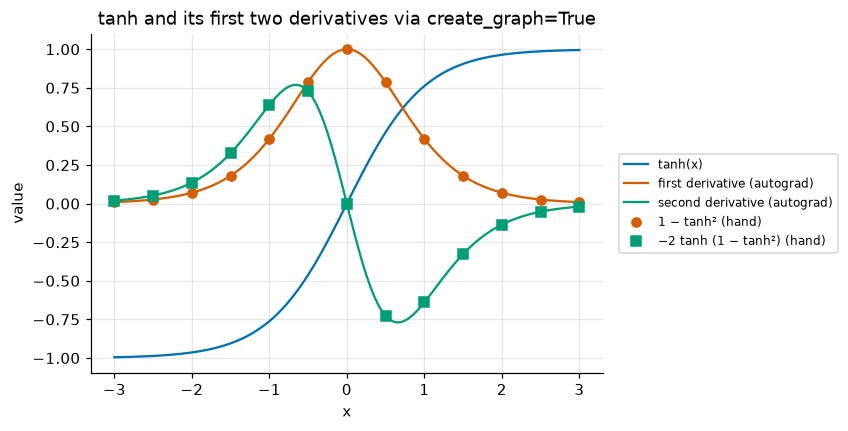

max error, 1st derivative: 1.7695128917694092e-08
max error, 2nd derivative: 3.5390257835388184e-08


In [61]:
xs = torch.linspace(-3, 3, 121, requires_grad=True)          # (121,)
ys = torch.tanh(xs)
(d1,) = torch.autograd.grad(ys.sum(), xs, create_graph=True)  # (121,) first derivatives
(d2,) = torch.autograd.grad(d1.sum(), xs)                     # (121,) second derivatives

xs_np, t = xs.detach(), torch.tanh(xs.detach())
hand_d1, hand_d2 = 1 - t**2, -2 * t * (1 - t**2)
plt.plot(xs_np, ys.detach(), label="tanh(x)")
plt.plot(xs_np, d1.detach(), label="first derivative (autograd)")
plt.plot(xs_np, d2.detach(), label="second derivative (autograd)")
plt.plot(xs_np[::10], hand_d1[::10], "o", color=COLORS[1], label="1 − tanh² (hand)")
plt.plot(xs_np[::10], hand_d2[::10], "s", color=COLORS[2], label="−2 tanh (1 − tanh²) (hand)")
plt.xlabel("x")
plt.ylabel("value")
plt.title("tanh and its first two derivatives via create_graph=True")
plt.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()
print("max error, 1st derivative:", (d1.detach() - hand_d1).abs().max().item())
print("max error, 2nd derivative:", (d2 - hand_d2).abs().max().item())

The autograd curves pass through the hand-formula markers, with errors at `float32` rounding level. The first derivative peaks at $x = 0$, where tanh is steepest, and the second derivative is zero there, at the inflection point. Second derivatives appear later in the course only occasionally (for example, curvature arguments about optimizers); first derivatives are what training uses.

## 10. [GPU] Autograd on a device

Nothing in this notebook is specific to the CPU. Autograd records and runs the same graph on any device, and each gradient lives on the **same device as its leaf**. This cell repeats the section 3 vector example on the selected device (in `float32`, so it also works on MPS) and compares with the CPU result. On a CPU-only machine it skips itself.

In [62]:
if device.type == "cpu":
    print("No GPU selected; skipping. (Set up Colab with a GPU runtime to try this.)")
else:
    gen = torch.Generator().manual_seed(0)
    W_cpu = torch.randn(256, 512, generator=gen)
    x_cpu = torch.randn(512, generator=gen, requires_grad=True)
    x_dev = x_cpu.detach().to(device).requires_grad_(True)   # a leaf on the device
    W_dev = W_cpu.to(device)

    (torch.tanh(W_cpu @ x_cpu) ** 2).sum().backward()
    (torch.tanh(W_dev @ x_dev) ** 2).sum().backward()
    print("x_dev.grad lives on:", x_dev.grad.device)
    diff = (x_dev.grad.cpu() - x_cpu.grad).abs().max().item()
    print(f"max |CPU grad − {device.type.upper()} grad| = {diff:.2e}")

x_dev.grad lives on:

 mps:0
max |CPU grad − MPS grad| = 1.81e-05


## Exercises

### Exercise 1 (modify): two backward calls

The cell below computes the gradient of $y = x^3$ at $x = 2$ (where $dy/dx = 12$) twice in a row. Three switches control it:

- `ZERO_GRAD`: whether to reset `x.grad` before each backward.
- `REBUILD_GRAPH`: whether to recompute $y$ (rebuild the graph) before each backward, or build it once and call backward on it twice.
- `RETAIN_GRAPH`: the `retain_graph` argument passed to `backward()`.

Run it with the given settings. Then try: (1) `ZERO_GRAD = True`; (2) `REBUILD_GRAPH = False`; (3) `REBUILD_GRAPH = False, RETAIN_GRAPH = True`, with `ZERO_GRAD` both off and on. Explain each printed result in the markdown cell below.

In [63]:
ZERO_GRAD = False
REBUILD_GRAPH = True
RETAIN_GRAPH = False

x = torch.tensor(2.0, requires_grad=True)
y = x**3
for call in range(1, 3):
    if REBUILD_GRAPH:
        y = x**3
    if ZERO_GRAD:
        x.grad = None
    try:
        y.backward(retain_graph=RETAIN_GRAPH)
        print(f"call {call}: x.grad = {x.grad.item()}")
    except RuntimeError as error:
        print(f"call {call}: RuntimeError:", str(error).splitlines()[0][:70], "...")

call 1: x.grad = 12.0
call 2: x.grad = 24.0


*Your answer:*

### Exercise 2 (implement): a custom sigmoid

Implement `Sigmoid(torch.autograd.Function)` computing $\sigma(x) = 1 / (1 + e^{-x})$ elementwise. Its derivative can be written in terms of its **output**: $\sigma'(x) = \sigma(x)\,(1 - \sigma(x))$. So, unlike `Softplus` above, save the **output** $\sigma(x)$ in `forward` (not the input), and use it in `backward`. You may use `torch.sigmoid` inside `forward`.

The check runs `gradcheck`, compares with `torch.sigmoid`'s gradient, and confirms you saved the output.

<details>
<summary><b>💡 Hint</b></summary>

In `forward`: `y = torch.sigmoid(x)`, `ctx.save_for_backward(y)`, `return y`. In `backward`: `(y,) = ctx.saved_tensors` and return `grad_output * y * (1 - y)`. Don't forget the `grad_output` factor.

</details>

In [ ]:
class Sigmoid(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        # YOUR CODE HERE
        raise NotImplementedError

    @staticmethod
    def backward(ctx, grad_output):
        # YOUR CODE HERE
        raise NotImplementedError

In [ ]:
_x = torch.linspace(-6, 6, 13, dtype=torch.float64, requires_grad=True)
_y = Sigmoid.apply(_x)
check_close(_y.detach(), torch.sigmoid(_x.detach()), "Sigmoid forward")
_saved = _y.grad_fn.saved_tensors
check(len(_saved) == 1 and torch.equal(_saved[0], _y.detach()), "save exactly one tensor: the output σ(x)")
check(torch.autograd.gradcheck(Sigmoid.apply, (_x,), raise_exception=False), "gradcheck failed: check the backward formula and the grad_output factor")
_v = torch.linspace(-1, 1, 13, dtype=torch.float64)
(_mine,) = torch.autograd.grad(_y, _x, grad_outputs=_v)
_xr = _x.detach().clone().requires_grad_(True)
(_ref,) = torch.autograd.grad(torch.sigmoid(_xr), _xr, grad_outputs=_v)
check_close(_mine, _ref, "VJP of Sigmoid")
passed("Exercise 2")

### Exercise 3 (debug): gradient descent that never settles

`gradient_descent(w0, lr, steps)` should minimize $f(w) = (w - 3)^2$ from $w_0$ and return the list of iterates $[w_0, w_1, \dots, w_{\text{steps}}]$. With $\eta = 0.1$, section 6 showed $w_k = 3 + 0.8^k (w_0 - 3)$, which approaches 3. The buggy version below does not converge. Find and fix the bug.

<details>
<summary><b>💡 Hint</b></summary>

Print `w.grad` inside the loop of the buggy version. Compare it with $2(w - 3)$. What happens to `.grad` from one `backward()` to the next?

</details>

In [ ]:
def gradient_descent(w0, lr, steps):
    # Buggy version:
    #     w = torch.tensor(w0, requires_grad=True)
    #     history = [w.item()]
    #     for _ in range(steps):
    #         loss = (w - 3) ** 2
    #         loss.backward()
    #         with torch.no_grad():
    #             w -= lr * w.grad
    #         history.append(w.item())
    #     return history
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
_hist = gradient_descent(0.0, 0.1, 30)
check(len(_hist) == 31, f"expected 31 iterates (w0 plus 30 steps), got {len(_hist)}")
_expected = [3 + 0.8**k * (0.0 - 3) for k in range(31)]
check_close(torch.tensor(_hist), torch.tensor(_expected), "iterates", rtol=1e-4, atol=1e-5)
passed("Exercise 3")

For comparison, this cell runs the buggy loop and plots both trajectories (it does not depend on your fix):

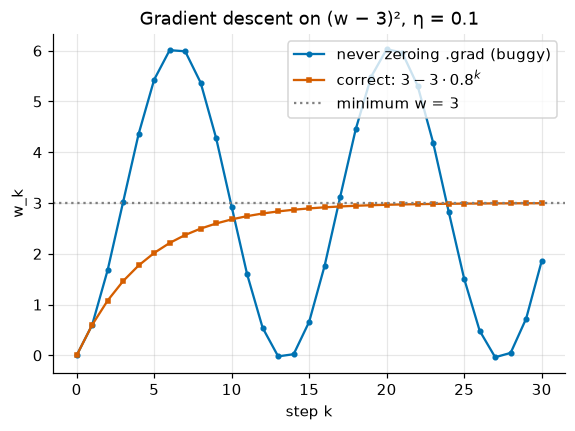

In [68]:
def buggy_gradient_descent(w0, lr, steps):
    w = torch.tensor(w0, requires_grad=True)
    history = [w.item()]
    for _ in range(steps):
        ((w - 3) ** 2).backward()
        with torch.no_grad():
            w -= lr * w.grad
        history.append(w.item())
    return history


steps = range(31)
plt.plot(steps, buggy_gradient_descent(0.0, 0.1, 30), "o-", markersize=3, label="never zeroing .grad (buggy)")
plt.plot(steps, [3 + 0.8**k * (0.0 - 3) for k in steps], "s-", markersize=3, label="correct: $3 - 3 \\cdot 0.8^k$")
plt.axhline(3, color="gray", linestyle=":", label="minimum w = 3")
plt.xlabel("step k")
plt.ylabel("w_k")
plt.title("Gradient descent on (w − 3)², η = 0.1")
plt.legend()
plt.show()

Without zeroing, `w.grad` after step $k$ holds the **sum** of all gradients so far, so the update keeps pushing in the old direction long after $w$ has passed 3. The iterates oscillate around the minimum with an amplitude that does not shrink.

### Exercise 4 (investigate): autograd vs finite differences at scale

For $f(\mathbf{x}) = \sum_{i=1}^{n} \sin(x_i)\, x_i^2$ with $n = 100$, the exact gradient is $\partial f / \partial x_i = \cos(x_i)\,x_i^2 + 2x_i \sin(x_i)$. The scaffold computes the gradient three ways, in `float32` and in `float64`, and compares each with the exact formula evaluated in `float64`:

- **Forward differences** $\big(f(\mathbf{x} + h\mathbf{e}_i) - f(\mathbf{x})\big)/h$, for every $i$: $n + 1$ evaluations of $f$.
- **Central differences** $\big(f(\mathbf{x} + h\mathbf{e}_i) - f(\mathbf{x} - h\mathbf{e}_i)\big)/(2h)$: $2n$ evaluations.
- **Autograd:** one forward and one backward pass.

1. Run it. Which $h$ is best for each scheme and dtype, and what is the best error achievable? Compare with autograd's error.
2. Explain the V shape of the finite-difference curves using notebook 03's truncation + rounding analysis. Why do the optimal $h$ differ between forward and central differences, and between dtypes?
3. Conclude: why is autograd used for training, and finite differences only for checking?

<details>
<summary><b>💡 Hint</b></summary>

Truncation error is about $h |f''|/2$ for forward and $h^2 |f'''|/6$ for central differences; rounding error is about $\epsilon |f| / h$. Balance the two terms to estimate the best $h$ and the best error, with $\epsilon \approx 1.2 \times 10^{-7}$ (`float32`) or $2.2 \times 10^{-16}$ (`float64`).

</details>

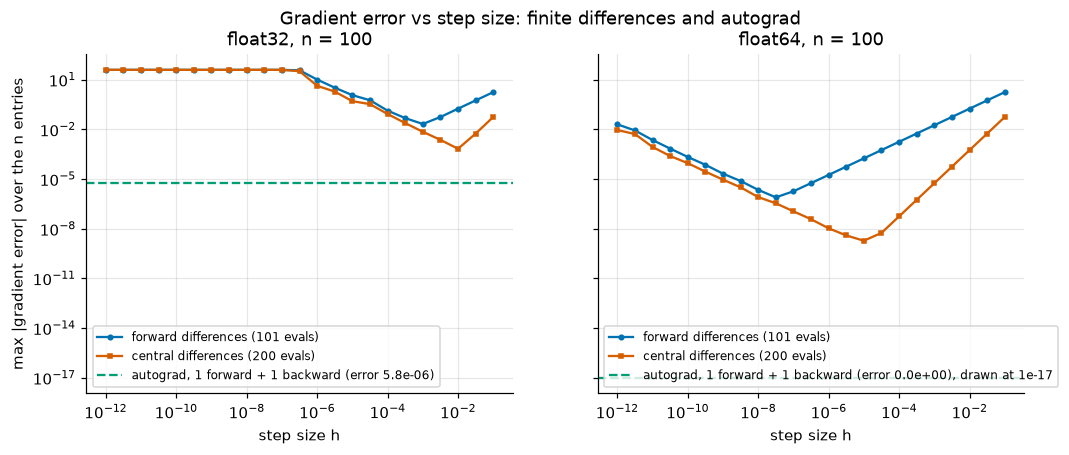

 torch.float32: best forward 2.1e-02 at h=1e-03 | best central 6.8e-04 at h=1e-02 | autograd 5.8e-06
 torch.float64: best forward 7.9e-07 at h=3e-08 | best central 1.9e-09 at h=1e-05 | autograd 0.0e+00


In [69]:
def f_many(X):
    """f applied along the last dimension: (..., n) -> (...)."""
    return (torch.sin(X) * X**2).sum(dim=-1)


n = 100
x_ref = 2 * torch.randn(n, generator=torch.Generator().manual_seed(0), dtype=torch.float64)  # (n,)
exact = torch.cos(x_ref) * x_ref**2 + 2 * x_ref * torch.sin(x_ref)                         # (n,) float64
hs = torch.logspace(-12, -1, 23, dtype=torch.float64).tolist()

results = {}
for dtype in (torch.float32, torch.float64):
    x = x_ref.to(dtype)
    eye = torch.eye(n, dtype=dtype)                       # (n, n): row i is e_i
    fx = f_many(x)
    fwd_err, ctr_err = [], []
    for h in hs:
        f_plus = f_many(x + h * eye)                      # (n,): n evaluations, f(x + h e_i)
        f_minus = f_many(x - h * eye)                     # (n,): n evaluations, f(x - h e_i)
        fwd = (f_plus - fx) / h
        ctr = (f_plus - f_minus) / (2 * h)
        fwd_err.append((fwd.double() - exact).abs().max().item())
        ctr_err.append((ctr.double() - exact).abs().max().item())
    xg = x.clone().requires_grad_(True)
    f_many(xg).backward()                                 # 1 forward + 1 backward
    ag_err = (xg.grad.double() - exact).abs().max().item()
    results[dtype] = (fwd_err, ctr_err, ag_err)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (dtype, (fwd_err, ctr_err, ag_err)) in zip(axes, results.items()):
    name = str(dtype).replace("torch.", "")
    ax.loglog(hs, fwd_err, "o-", markersize=3, label=f"forward differences ({n + 1} evals)")
    ax.loglog(hs, ctr_err, "s-", markersize=3, label=f"central differences ({2 * n} evals)")
    ag_label = f"autograd, 1 forward + 1 backward (error {ag_err:.1e})"
    if ag_err == 0:
        ag_label += ", drawn at 1e-17"
    ax.axhline(max(ag_err, 1e-17), color=COLORS[2], linestyle="--", label=ag_label)
    ax.set_xlabel("step size h")
    ax.set_title(f"{name}, n = {n}")
    ax.legend(fontsize=8)
axes[0].set_ylabel("max |gradient error| over the n entries")
fig.suptitle("Gradient error vs step size: finite differences and autograd")
plt.show()

for dtype, (fwd_err, ctr_err, ag_err) in results.items():
    i_f, i_c = min(range(len(hs)), key=fwd_err.__getitem__), min(range(len(hs)), key=ctr_err.__getitem__)
    print(f"{str(dtype):>14}: best forward {fwd_err[i_f]:.1e} at h={hs[i_f]:.0e} | "
          f"best central {ctr_err[i_c]:.1e} at h={hs[i_c]:.0e} | autograd {ag_err:.1e}")

*Your conclusion:*

## Summary and what's next

- Setting `requires_grad=True` makes PyTorch record a **computational graph** as you compute; `backward()` walks it in reverse and stores $\partial L / \partial \text{leaf}$ in each leaf's `.grad`.
- Each graph node implements a **vector–Jacobian product**. Reverse mode chains them from the scalar loss back to the inputs, never forming a full Jacobian, so a gradient costs a small multiple of one forward pass however many parameters there are. Finite differences need $2n$ evaluations and are only approximate.
- Non-scalar outputs need an explicit $\mathbf{v}$ (`gradient=` / `grad_outputs=`); `torch.autograd.grad` returns gradients instead of storing them.
- `.grad` **accumulates** across backward calls. Reset it (`= None` or `.zero_()`) before each new gradient. Backward frees saved tensors unless `retain_graph=True`.
- `detach()`, `torch.no_grad()` and `torch.inference_mode()` turn tracking off. Parameter updates go inside `no_grad`, in place, on the leaf itself.
- In-place changes to saved tensors are caught by the **version counter**; `.data` bypasses it and produces silently wrong gradients.
- A custom `torch.autograd.Function` pairs a forward with a hand-written VJP; `gradcheck` in `float64` verifies it against finite differences.

We now have losses (notebook 04) and gradients of anything we can compute (this notebook). Notebook 06 puts them together: it fits a linear regression model, first with hand-derived gradients, then with autograd, then with PyTorch's `nn.Module` and optimizers — and shows that mean squared error is the Gaussian maximum-likelihood loss.